### SciKit-Learn

In [1]:
%pip install --upgrade scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 117.9 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [2]:
import sklearn
print(sklearn.__version__)

1.9.1


In [3]:
from sklearn.datasets import load_diabetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
x , y = load_diabetes(return_X_y=True)

In [5]:
print(x.shape)
print(y.shape)

(442, 10)
(442,)


In [6]:
x[1]

array([-0.00188202, -0.04464164, -0.05147406, -0.02632753, -0.00844872,
       -0.01916334,  0.07441156, -0.03949338, -0.06833155, -0.09220405])

In [7]:
y[1]

np.float64(75.0)

In [8]:
from sklearn.neighbors import KNeighborsRegressor

In [9]:
model = KNeighborsRegressor().fit(x,y)

In [10]:
pred = model.predict(x)

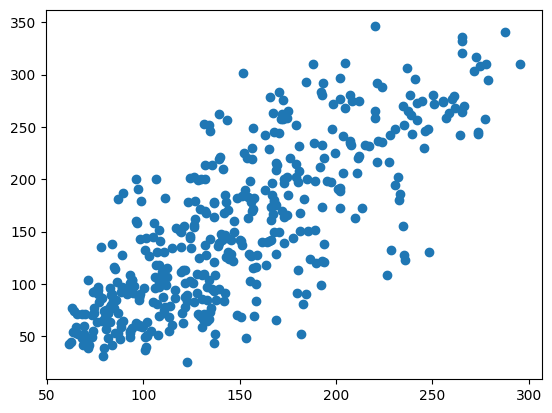

In [11]:
plt.scatter(pred, y)

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [13]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=1))
])
pipe.get_params()

{'memory': None,
 'steps': [('scale', StandardScaler()),
  ('model', KNeighborsRegressor(n_neighbors=1))],
 'transform_input': None,
 'verbose': False,
 'scale': StandardScaler(),
 'model': KNeighborsRegressor(n_neighbors=1),
 'scale__copy': True,
 'scale__with_mean': True,
 'scale__with_std': True,
 'model__algorithm': 'auto',
 'model__leaf_size': 30,
 'model__metric': 'minkowski',
 'model__metric_params': None,
 'model__n_jobs': None,
 'model__n_neighbors': 1,
 'model__p': 2,
 'model__weights': 'uniform'}

In [14]:
model = GridSearchCV(
    estimator = pipe,
    param_grid = {'model__n_neighbors': [1,2,3,4,5,6,7,8,9,10]},
    cv = 3
    )

In [15]:
model.fit(x,y)
pd.DataFrame(model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003627,0.000401,0.003659,0.000151,1,{'model__n_neighbors': 1},0.105976,0.124092,-0.158523,0.023849,0.129168,10
1,0.004361,0.000801,0.006462,0.002059,2,{'model__n_neighbors': 2},0.268889,0.339379,0.264563,0.290944,0.034295,9
2,0.006377,0.000878,0.007334,0.000615,3,{'model__n_neighbors': 3},0.333057,0.382744,0.356899,0.357567,0.020290,8
3,0.007466,0.000842,0.006532,0.001972,4,{'model__n_neighbors': 4},0.342407,0.404701,0.409910,0.385673,0.030668,6
4,0.004080,0.001143,0.005412,0.002277,5,{'model__n_neighbors': 5},0.358865,0.377198,0.412549,0.382871,0.022280,7
5,0.005335,0.003018,0.005400,0.001883,6,{'model__n_neighbors': 6},0.372665,0.389923,0.436389,0.399659,0.026911,5
6,0.005276,0.001755,0.005703,0.001738,7,{'model__n_neighbors': 7},0.412584,0.393681,0.446147,0.417471,0.021696,4
7,0.003192,0.000266,0.005812,0.001751,8,{'model__n_neighbors': 8},0.414478,0.409779,0.485850,0.436702,0.034806,3
8,0.003658,0.000191,0.004294,0.000237,9,{'model__n_neighbors': 9},0.414191,0.412035,0.528462,0.451563,0.054383,2
9,0.003501,0.000130,0.004039,0.000092,10,{'model__n_neighbors': 10},0.408989,0.405303,0.544371,0.452888,0.064706,1


In [16]:
# Accessing the best parameters and score from the Grid Search
print(f"Best Parameters: {model.best_params_}")
print(f"Best Cross-Validation R2 Score: {model.best_score_:.4f}")

Best Parameters: {'model__n_neighbors': 10}
Best Cross-Validation R2 Score: 0.4529


In [17]:
pred = model.predict(x)

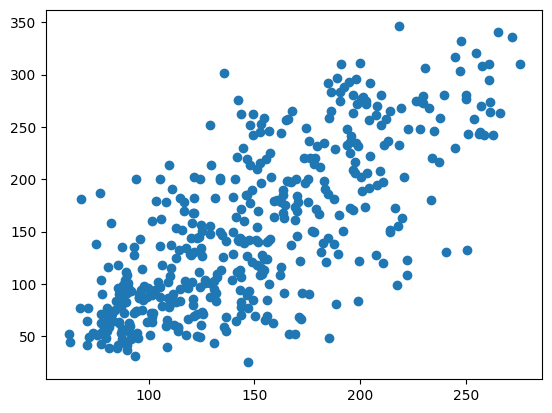

In [18]:
plt.scatter(pred, y)

### Pre-Processing

In [19]:
print(load_diabetes()['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [20]:
d = load_diabetes(as_frame=True)

print(d)

{'data':           age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  
0   -0.002592  0.019907 -0.017

In [21]:
x = d.data
y = d.target

In [22]:
x.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [23]:
y.head()

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


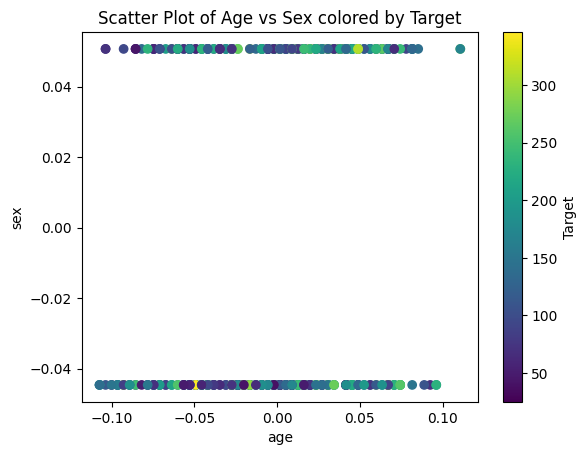

In [24]:
plt.scatter(x.iloc[:, 0], x.iloc[:, 1], c=y)

plt.xlabel(x.columns[0])
plt.ylabel(x.columns[1])
plt.title("Scatter Plot of Age vs Sex colored by Target")
plt.colorbar(label="Target")
plt.show()

In [33]:
x = StandardScaler().fit_transform(x)
y = StandardScaler().fit_transform(np.asarray(y).reshape(-1, 1)).flatten()

print(x.shape)
print(y.shape)

(442, 10)
(442,)


In [36]:
from sklearn.preprocessing import QuantileTransformer

x = QuantileTransformer(n_quantiles = 442, output_distribution='normal').fit_transform(x)
y = QuantileTransformer(n_quantiles = 442, output_distribution='normal').fit_transform(y.reshape(-1, 1)).flatten()

print(x.shape)
print(y.shape)

(442, 10)
(442,)


### Metrics

In [37]:
import kagglehub

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [38]:
import os

print(os.listdir(path))
file = os.path.join(path, "creditcard.csv")
print(file)

['creditcard.csv']
/kaggle/input/creditcardfraud/creditcard.csv


In [39]:
ccf = pd.read_csv('/kaggle/input/creditcardfraud/creditcard.csv')
ccf.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [41]:
ccf.shape

(284807, 31)

In [42]:
ccf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [43]:
ccf.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [44]:
ccf.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [45]:
x = ccf.drop(columns = ['Time', 'Amount', 'Class']).values
y = ccf['Class'].values

f"Shapes of X: {x.shape} and Y: {y.shape}, #Fraud Cases = {y.sum()}"

'Shapes of X: (284807, 28) and Y: (284807,), #Fraud Cases = 492'

In [46]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(class_weight={0:1, 1:2})
model.fit(x,y).predict(x).sum()

np.int64(434)

In [56]:
from collections import Counter
from sklearn.ensemble import IsolationForest

model = IsolationForest().fit(x)
Counter(model.predict(x))

Counter({np.int64(1): 273314, np.int64(-1): 11493})

In [57]:
np.where(model.predict(x) == -1, 1, 0)

array([0, 0, 0, ..., 0, 0, 0], shape=(284807,))

In [58]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score

# def min_recall_precision(y_true, y_pred):
#   recall = recall_score(y_true, y_pred, zero_division=0)
#   precision = precision_score(y_true, y_pred, zero_division=0)
#   return min(recall, precision)

# grid = GridSearchCV(
#     estimator = LogisticRegression(),
#     param_grid = {
#       'class_weight': [{0: 1, 1: v} for v in np.linspace(1, 20, 30)]
#       },
#     scoring = {
#         'accuracy': make_scorer(accuracy_score),
#         'precision': make_scorer(precision_score),
#         'recall': make_scorer(recall_score),
#         'min_both': make_scorer(min_recall_precision)
#     },
#     refit = 'min_both',
#     return_train_score = True,
#     cv = 10,
#     n_jobs= -1
# )

def outlier_precision(model, x, y):
  preds = model.predict(x)
  return precision_score(y, np.where(preds == -1, 1, 0))

def outlier_recall(model, x, y):
  preds = model.predict(x)
  return recall_score(y, np.where(preds == -1, 1, 0))

grid = GridSearchCV(
    estimator = IsolationForest(),
    param_grid = {
        'contamination': np.linspace(0.001, 0.02, 10)
    },
    scoring = {
        'precision': outlier_precision,
        'recall': outlier_recall,
    },
    refit = 'precision',
    cv = 5,
    n_jobs = -1
)

grid.fit(x, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",IsolationForest()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'contamination': array([0.001 ..., 0.02 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'precision': <function out...x78a22aa5eac0>, 'recall': <function out...x78a247f23ec0>}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbos

In [60]:
# Map Isolation Forest predictions: -1 (anomaly) -> 1 (fraud), 1 (normal) -> 0
y_pred_raw = grid.predict(x)
y_pred_binary = np.where(y_pred_raw == -1, 1, 0)

print("Accuracy Score: ", accuracy_score(y, y_pred_binary))
print("Precision Score: ", precision_score(y, y_pred_binary))
print("Recall Score: ", recall_score(y, y_pred_binary))

Accuracy Score:  0.9978617098596594
Precision Score:  0.29473684210526313
Recall Score:  0.17073170731707318


In [65]:
# plt.figure(figsize=(12, 4))
# df = pd.DataFrame(grid.cv_results_)

# for score in ['mean_test_accuracy', 'mean_test_precision', 'mean_test_recall']:
#     plt.plot(df['param_class_weight'].apply(lambda x: x[1]), df[score], label=score)
#     plt.legend()

<Figure size 1200x400 with 0 Axes>

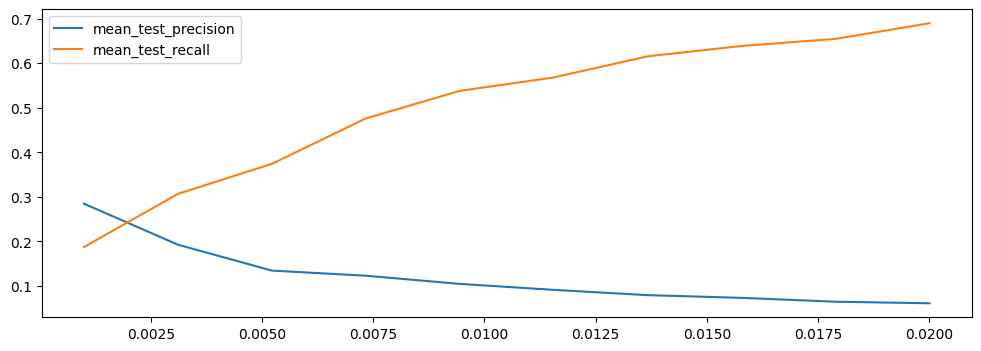

In [67]:
plt.figure(figsize=(12, 4))

df2 = pd.DataFrame(grid.cv_results_)

# for score in ['mean_test_min_both', 'mean_test_precision', 'mean_test_recall']:
#     plt.plot([_[1] for _ in df['param_class_weight']], df[score], label=score)
#     plt.legend()

for score in ['mean_test_precision', 'mean_test_recall']:
    plt.plot(df2['param_contamination'],
             df2[score],
             label=score)
    plt.legend()